# 使用 YOLO11L MTK FP16 TFLite 模型进行测试

本页将加载并测试 `/home/visuals/Code/yolo/yolo11l_mtk_fp16.tflite` 模型，支持：
- 单张图片预测（显示类别与概率条形图）
- 文件夹批量预测（带统计信息）
- 自动检测输入尺寸、数据类型与通道顺序（NHWC/NCHW）

如未安装 TFLite 运行时，将尝试使用 TensorFlow Lite 的解释器。

In [24]:
# 加载 TFLite 解释器并自检（优先使用 TensorFlow 的 Interpreter，兼容 Select TF Ops）
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '1')  # 显示WARNING以上日志

# 优先使用 tensorflow.lite.Interpreter，失败再退回 tflite_runtime
BACKENDS = []
try:
    import tensorflow as tf  # noqa: F401
    from tensorflow.lite import Interpreter as TFInterpreter  # type: ignore
    BACKENDS.append(("tensorflow.lite", TFInterpreter))
except Exception:
    pass

try:
    from tflite_runtime.interpreter import Interpreter as RTInterpreter  # type: ignore
    BACKENDS.append(("tflite-runtime", RTInterpreter))
except Exception:
    pass

if not BACKENDS:
    raise ImportError("未找到 TFLite 运行时。请安装 tflite-runtime 或 TensorFlow。\n建议: pip install tflite-runtime 或 pip install tensorflow==2.12.*")

import numpy as np
import cv2, time

# 模型路径（支持 FP16/UINT8 TFLite）
TFLITE_MODEL_PATH = "/home/visuals/Code/yolo/yolo11l_mtk_fp16.tflite"
assert os.path.exists(TFLITE_MODEL_PATH), f"模型文件不存在: {TFLITE_MODEL_PATH}"
assert os.access(TFLITE_MODEL_PATH, os.R_OK), f"模型文件不可读: {TFLITE_MODEL_PATH}"

# 简单校验：检查文件头是否包含 TFL3 魔数
with open(TFLITE_MODEL_PATH, 'rb') as f:
    header = f.read(8)
if b'TFL3' not in header:
    print("⚠️ 警告：文件头未检测到 'TFL3' 标记，这可能不是有效的 TFLite 模型。")

# 逐个后端尝试加载
interpreter = None
TFLITE_BACKEND = None
last_error = None
for name, Cls in BACKENDS:
    try:
        interpreter = Cls(model_path=TFLITE_MODEL_PATH, num_threads=max(1, (os.cpu_count() or 2) // 2))
        TFLITE_BACKEND = name
        break
    except Exception as e:
        last_error = e
        print(f"❌ 使用 {name} 加载失败: {e}")

if interpreter is None:
    raise RuntimeError(f"所有后端均加载失败，请确认模型兼容性与依赖。最后错误: {last_error}")

# 分配张量并打印关键信息
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# 仅支持单输入/单输出分类模型（常见）
assert len(input_details) == 1, f"期望1个输入，得到{len(input_details)}"
assert len(output_details) == 1, f"期望1个输出，得到{len(output_details)}"

in_det = input_details[0]
out_det = output_details[0]

in_shape = list(in_det['shape'])  # e.g., [1, 416, 416, 3] 或 [1, 3, 416, 416]
in_dtype = in_det['dtype']        # np.float16 / np.float32 / np.uint8
out_dtype = out_det['dtype']

# 判定通道维度位置
if len(in_shape) == 4 and in_shape[3] == 3:
    LAYOUT = 'NHWC'
    IN_H, IN_W = in_shape[1], in_shape[2]
elif len(in_shape) == 4 and in_shape[1] == 3:
    LAYOUT = 'NCHW'
    IN_H, IN_W = in_shape[2], in_shape[3]
else:
    # 回退：假设 NHWC 416x416
    LAYOUT = 'NHWC'
    IN_H, IN_W = (416, 416)

# 量化参数（若为uint8/int8模型会提供scale/zero_point）
in_q = in_det.get('quantization', (0.0, 0))
out_q = out_det.get('quantization', (0.0, 0))

# 打印信息
file_size_mb = os.path.getsize(TFLITE_MODEL_PATH) / (1024 * 1024)
print("TFLite Backend:", TFLITE_BACKEND)
print(f"Model: {TFLITE_MODEL_PATH} ({file_size_mb:.2f} MB)")
print("Input shape:", in_shape, "dtype:", in_dtype, "layout:", LAYOUT)
print("Output shape:", out_det['shape'], "dtype:", out_dtype)
print("Input quantization (scale, zero_point):", in_q)
print("Output quantization (scale, zero_point):", out_q)

TFLite Backend: tflite-runtime
Model: /home/visuals/Code/yolo/yolo11l_mtk_fp16.tflite (11.69 MB)
Input shape: [1, 3, 416, 416] dtype: <class 'numpy.uint8'> layout: NCHW
Output shape: [1 2] dtype: <class 'numpy.uint8'>
Input quantization (scale, zero_point): (0.003921568859368563, 0)
Output quantization (scale, zero_point): (0.00390625, 0)


In [25]:
# 预处理与推理函数（TFLite）
import matplotlib.pyplot as plt

CLASS_NAMES = {0: 'Non-PPT', 1: 'PPT'}  # 可按需修改


def _preprocess_image_for_tflite(img_path):
    img = cv2.imread(img_path)
    if img is None:
        raise FileNotFoundError(f"无法读取图片: {img_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IN_W, IN_H), interpolation=cv2.INTER_LINEAR)

    # 归一化到 [0,1] 作为“真实值”
    img = img.astype(np.float32) / 255.0

    if LAYOUT == 'NHWC':
        real_tensor = img[None, ...]  # (1, H, W, 3)
    else:  # 'NCHW'
        real_tensor = np.transpose(img, (2, 0, 1))[None, ...]  # (1, 3, H, W)

    # 匹配 TFLite 输入 dtype（fp16/fp32/uint8）
    if in_dtype == np.uint8:
        # 将“真实值”量化到uint8: q = real/scale + zero_point
        scale, zero_point = in_det.get('quantization', (1.0, 0))
        # 防御：避免scale为0
        scale = scale if scale not in (None, 0.0) else 1.0
        input_tensor = (real_tensor / scale + zero_point).round().clip(0, 255).astype(np.uint8)
    elif in_dtype == np.float16:
        input_tensor = real_tensor.astype(np.float16)
    else:  # 默认float32
        input_tensor = real_tensor.astype(np.float32)

    return input_tensor


def _softmax(x):
    x = x - np.max(x, axis=-1, keepdims=True)
    e = np.exp(x)
    return e / np.sum(e, axis=-1, keepdims=True)


def infer_tflite(img_path, return_probs=False):
    input_tensor = _preprocess_image_for_tflite(img_path)
    interpreter.set_tensor(in_det['index'], input_tensor)
    start = time.time()
    interpreter.invoke()
    elapsed = (time.time() - start) * 1000

    raw_output = interpreter.get_tensor(out_det['index'])  # 可能为 uint8 或 float

    # 若输出为量化整型（常见为uint8），先反量化到“真实值”
    if out_dtype == np.uint8:
        out_scale, out_zero = out_det.get('quantization', (0.0, 0))
        if out_scale not in (None, 0.0):
            output = out_scale * (raw_output.astype(np.float32) - out_zero)
        else:
            output = raw_output.astype(np.float32)  # 无量化参数则直接转float
    else:
        output = raw_output.astype(np.float32)

    # 分类通常对logits做softmax；若模型输出本身已是概率，可将return_probs=False
    probs = _softmax(output) if return_probs else output

    top1 = int(np.argmax(probs, axis=-1)[0])
    top1conf = float(probs[0, top1])
    return top1, top1conf, probs[0].tolist(), elapsed


def predict_single_image_tflite(image_path):
    # 字体设置，避免中文乱码
    plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'SimHei', 'Arial Unicode MS']
    plt.rcParams['axes.unicode_minus'] = False

    top1, conf, probs, elapsed_ms = infer_tflite(image_path)

    # 可视化
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        print(f"读取图片失败: {image_path}")
        return
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(7, 5))
    plt.imshow(img_rgb)
    title = f"Pred: {CLASS_NAMES.get(top1, top1)}  Conf: {conf:.4f}  ({elapsed_ms:.1f} ms)"
    plt.title(title)
    plt.axis('off')
    plt.show()

    # 概率柱状图
    labels = [CLASS_NAMES.get(i, str(i)) for i in range(len(probs))]
    plt.figure(figsize=(6, 3.5))
    bars = plt.bar(labels, probs, color=['steelblue', 'orange'][:len(probs)])
    plt.ylim(0, 1)
    plt.ylabel('Probability')
    plt.title('TFLite Prediction Probability')
    for b in bars:
        h = b.get_height()
        plt.text(b.get_x() + b.get_width()/2, h + 0.01, f"{h:.3f}", ha='center', va='bottom')
    plt.show()

    print(f"Predicted Class: {top1} ({CLASS_NAMES.get(top1, top1)})")
    print(f"Confidence: {conf:.4f}")
    if len(probs) >= 2:
        print(f"Class 0 Probability: {probs[0]:.4f}")
        print(f"Class 1 Probability: {probs[1]:.4f}")
    print(f"Latency: {elapsed_ms:.1f} ms")


def predict_folder_tflite(folder_path, limit=20, verbose=False):
    # 收集图片
    import glob
    exts = ['jpg', 'jpeg', 'png', 'JPG', 'JPEG', 'PNG']
    image_files = []
    for ext in exts:
        image_files.extend(glob.glob(os.path.join(folder_path, f"*.{ext}")))
    if not image_files:
        print(f"文件夹无图片: {folder_path}")
        return {0: 0, 1: 0}, []

    if limit is not None and isinstance(limit, int) and limit > 0:
        image_files = image_files[:limit]

    results_dict = {}
    predictions = []

    for p in image_files:
        top1, conf, probs, elapsed_ms = infer_tflite(p)
        results_dict[top1] = results_dict.get(top1, 0) + 1
        predictions.append({
            'path': p,
            'filename': os.path.basename(p),
            'pred_class': top1,
            'confidence': conf,
            'probs': probs,
            'latency_ms': elapsed_ms
        })
        if verbose:
            print(f"{os.path.basename(p)} -> {CLASS_NAMES.get(top1, top1)} ({conf:.3f})  {elapsed_ms:.1f}ms")

    return results_dict, predictions

单张图片测试: /home/visuals/Code/datasets/2.png


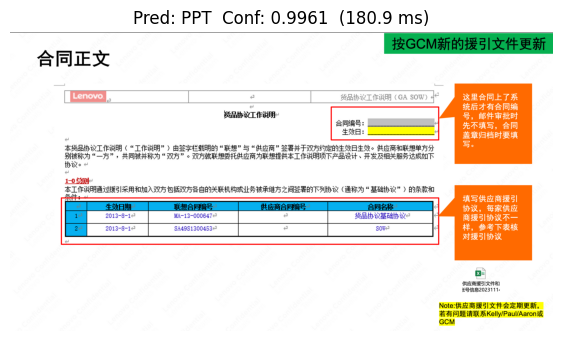

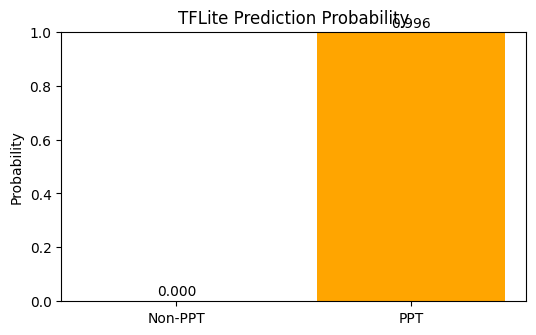

Predicted Class: 1 (PPT)
Confidence: 0.9961
Class 0 Probability: 0.0000
Class 1 Probability: 0.9961
Latency: 180.9 ms


In [27]:
# 快速测试：单张图片与批量统计
# 可根据需要修改路径
single_image_path = "/home/visuals/Code/datasets/2.png"
folder_path = "/home/visuals/Code/datasets"  # 默认限制前20张，避免处理过多

if os.path.exists(single_image_path):
    print("单张图片测试:", single_image_path)
    predict_single_image_tflite(single_image_path)
else:
    print(f"图片不存在: {single_image_path}")


In [29]:
folder_path = "/home/visuals/Code/datasets/ppt_dataset13/train/1"  # 默认限制前20张，避免处理过多
if os.path.isdir(folder_path):
    print("\n批量测试:", folder_path)
    results_dict, predictions = predict_folder_tflite(folder_path, limit=20000, verbose=False)
    total = sum(results_dict.values())
    print("\nStatistics:")
    if total > 0:
        for k in sorted(results_dict.keys()):
            name = CLASS_NAMES.get(k, str(k))
            print(f"Class {k} ({name}): {results_dict[k]} ({results_dict[k]/total:.2%})")
        print(f"Total: {total}")
    else:
        print("No images processed.")
else:
    print(f"文件夹不存在: {folder_path}")


批量测试: /home/visuals/Code/datasets/ppt_dataset13/train/1

Statistics:
Class 0 (Non-PPT): 156 (4.43%)
Class 1 (PPT): 3369 (95.57%)
Total: 3525


In [19]:
import os, shutil, glob
from pathlib import Path

src_dirs = ['/home/visuals/Code/data1', '/home/visuals/Code/data2']
dst_dir = '/home/visuals/Code/datasets/ppt_dataset13/train/1'
os.makedirs(dst_dir, exist_ok=True)

# 支持的图片扩展名
exts = ['jpg', 'jpeg', 'png', 'bmp', 'JPG', 'JPEG', 'PNG', 'BMP']

# 统计目标文件夹已有文件名，避免重复
existing_files = set(os.listdir(dst_dir))

# 生成唯一新文件名
def get_unique_name(base_name, ext, used_names):
    idx = 1
    new_name = f'{base_name}{ext}'
    while new_name in used_names:
        new_name = f'{base_name}_{idx}{ext}'
        idx += 1
    used_names.add(new_name)
    return new_name

copied = 0
used_names = set(existing_files)
for src_dir in src_dirs:
    for ext in exts:
        for img_path in glob.glob(os.path.join(src_dir, f'*.{ext}')):
            fname = Path(img_path).stem
            extname = Path(img_path).suffix
            new_name = get_unique_name(fname, extname, used_names)
            dst_path = os.path.join(dst_dir, new_name)
            shutil.copy2(img_path, dst_path)
            copied += 1
print(f'已复制 {copied} 张图片到 {dst_dir}，所有文件名均已去重。')

已复制 55 张图片到 /home/visuals/Code/datasets/ppt_dataset13/train/1，所有文件名均已去重。
